# 03 — Multi-Model Benchmarking, Cost-Loss Analysis & Threshold Tuning
**Project:** Insurance Claim Fraud Detection — Major Project Phase 1  
**Objective:** Rigorously benchmark multiple classifiers using 5-Fold Stratified Cross-Validation. Optimize decision threshold based on business financial loss ($50,000 FN vs $500 FP).

In [1]:
from pathlib import Path

import sys

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns



sys.path.insert(0, str(Path.cwd().parent))

from src.train import train_and_benchmark

from src.evaluate import find_optimal_threshold, compute_financial_loss

import joblib

## 1. Execute Benchmark & Pipeline Training Engine

In [2]:
champion_pipeline, metadata = train_and_benchmark()

INSURANCE CLAIM FRAUD DETECTION - PIPELINE TRAINING ENGINE
[+] Loaded 1000 claims.
[+] Stratified Train: 800 claims (198 frauds).
[+] Stratified Test:  200 claims (49 frauds).

[+] Running 5-Fold Stratified Cross-Validation Benchmark...


c:\Users\chman\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


    - Cost-Weighted Logistic Regression   | PR-AUC: 0.621 | ROC-AUC: 0.843 | F1: 0.683
    - Balanced Random Forest              | PR-AUC: 0.607 | ROC-AUC: 0.842 | F1: 0.635
    - Gradient Boosting Classifier        | PR-AUC: 0.650 | ROC-AUC: 0.854 | F1: 0.661
    - Scale-Weighted XGBoost              | PR-AUC: 0.669 | ROC-AUC: 0.862 | F1: 0.702

[★] Champion Model Selected: Scale-Weighted XGBoost (Mean PR-AUC: 0.669)

[+] Held-Out Test Set Performance (Default 0.5 Threshold):
    - Fraud Recall:     79.6%
    - Fraud Precision:  63.9%
    - Fraud F1-Score:   0.709
    - Test ROC-AUC:     0.838
    - Test PR-AUC:      0.597
    - Confusion Matrix: TP=39, FP=22, FN=10, TN=129

[+] Financial Cost Optimization:
    - Default 0.50 Threshold Loss: $511,000.00
    - Optimal Business Cutoff (θ*): 0.05
    - Minimized Expected Loss:     $62,000.00

[✔] Production Pipeline saved to: C:\Users\chman\Desktop\insurance fraud detection\models\best_fraud_pipeline.joblib
[✔] Metadata saved to: C:\User

## 2. Cost-Benefit Threshold Curve
Plot the relationship between the decision threshold and business financial loss.

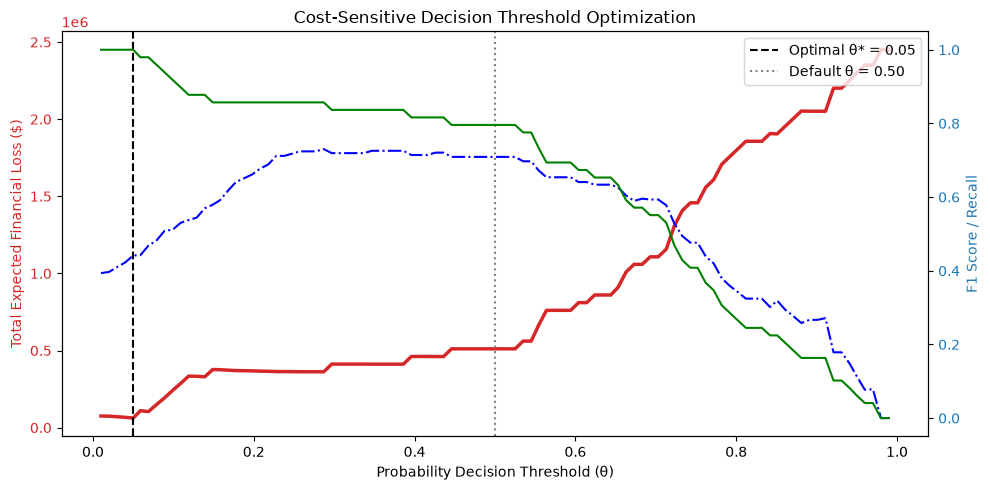

In [3]:
# Load test split for threshold visualization

from src.data_loader import load_raw_data, parse_dates_and_target, get_stratified_split

clean_df = parse_dates_and_target(load_raw_data())

_, X_test, _, y_test = get_stratified_split(clean_df, test_size=0.20)

y_test_prob = champion_pipeline.predict_proba(X_test)[:, 1]



best_th, min_loss, df_cost = find_optimal_threshold(y_test.values, y_test_prob)



fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'

ax1.set_xlabel('Probability Decision Threshold (θ)')

ax1.set_ylabel('Total Expected Financial Loss ($)', color=color)

ax1.plot(df_cost['threshold'], df_cost['total_financial_loss'], color=color, lw=2.5)

ax1.axvline(best_th, color='black', linestyle='--', label=f'Optimal θ* = {best_th:.2f}')

ax1.axvline(0.50, color='gray', linestyle=':', label='Default θ = 0.50')

ax1.tick_params(axis='y', labelcolor=color)

ax1.legend(loc='upper right')



ax2 = ax1.twinx()

color = 'tab:blue'

ax2.set_ylabel('F1 Score / Recall', color=color)

ax2.plot(df_cost['threshold'], df_cost['f1_score'], color='blue', label='F1-Score', linestyle='-.')

ax2.plot(df_cost['threshold'], df_cost['recall'], color='green', label='Recall', linestyle='-')

ax2.tick_params(axis='y', labelcolor=color)

plt.title('Cost-Sensitive Decision Threshold Optimization')

plt.tight_layout()

plt.show()